# Лабораторная работа №1

In [12]:
import gzip
import struct
import time
from math import ceil

import numpy as np
import matplotlib.pyplot as plt
from numpy import typing as npt

np.random.seed(42)


# ---------- Загрузка данных ----------

def load_images(path: str) -> npt.NDArray[np.uint8]:
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        if magic != 2051:
            raise ValueError(f"Неверный формат изображений: {path}")
        images = np.frombuffer(file.read(), dtype=np.uint8)
    return images.reshape(count, rows, cols)


def load_labels(path: str) -> npt.NDArray[np.uint8]:
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        if magic != 2049:
            raise ValueError(f"Неверный формат меток: {path}")
        labels = np.frombuffer(file.read(), dtype=np.uint8)
    return labels


train_images = load_images("./train-images.idx3-ubyte")
train_labels = load_labels("./train-labels.idx1-ubyte")
test_images = load_images("./t10k-images.idx3-ubyte")
test_labels = load_labels("./t10k-labels.idx1-ubyte")

print("Train:", train_images.shape, train_labels.shape)
print("Test: ", test_images.shape, test_labels.shape)

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)


x_train: (60000, 784) | x_test: (10000, 784)
Эпоха  1/20 | кросс-энтропия: 0.1622 | ошибка на train: 4.56% | время: 0.81 с
Эпоха  2/20 | кросс-энтропия: 0.1000 | ошибка на train: 2.82% | время: 0.79 с
Эпоха  3/20 | кросс-энтропия: 0.0735 | ошибка на train: 2.02% | время: 0.82 с
Эпоха  4/20 | кросс-энтропия: 0.0544 | ошибка на train: 1.43% | время: 0.78 с
Эпоха  5/20 | кросс-энтропия: 0.0516 | ошибка на train: 1.41% | время: 0.76 с
Эпоха  6/20 | кросс-энтропия: 0.0375 | ошибка на train: 0.96% | время: 0.74 с
Эпоха  7/20 | кросс-энтропия: 0.0321 | ошибка на train: 0.78% | время: 0.74 с
Эпоха  8/20 | кросс-энтропия: 0.0259 | ошибка на train: 0.57% | время: 0.74 с
Эпоха  9/20 | кросс-энтропия: 0.0218 | ошибка на train: 0.48% | время: 0.74 с
Эпоха 10/20 | кросс-энтропия: 0.0184 | ошибка на train: 0.35% | время: 0.74 с
Эпоха 11/20 | кросс-энтропия: 0.0156 | ошибка на train: 0.29% | время: 0.75 с
Эпоха 12/20 | кросс-энтропия: 0.0141 | ошибка на train: 0.21% | время: 0.80 с
Эпоха 13/20 | кросс

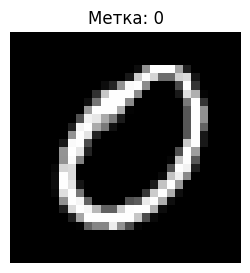

In [13]:
# ---------- Предобработка ----------

x_train = train_images.reshape(-1, 784).astype(np.float32) / 255.0
x_test = test_images.reshape(-1, 784).astype(np.float32) / 255.0

print("x_train:", x_train.shape, "| x_test:", x_test.shape)


# ---------- Гиперпараметры и инициализация ----------

INPUT_SIZE = 28 * 28
HIDDEN_SIZE = 300
OUTPUT_SIZE = 10
LEARNING_RATE = 0.1
BATCH_SIZE = 32
EPOCHS = 20


def init_params(n_in: int, n_hidden: int, n_out: int) -> dict[str, npt.NDArray[np.float32]]:
    """He-инициализация для ReLU, смещения нулевые."""
    return {
        "W1": (np.random.randn(n_in, n_hidden) * np.sqrt(2.0 / n_in)).astype(np.float32),
        "b1": np.zeros((1, n_hidden), dtype=np.float32),
        "W2": (np.random.randn(n_hidden, n_out) * np.sqrt(2.0 / n_hidden)).astype(np.float32),
        "b2": np.zeros((1, n_out), dtype=np.float32),
    }


params = init_params(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)


# ---------- Активации ----------

def relu(z: npt.NDArray[np.float32]) -> npt.NDArray[np.float32]:
    return np.maximum(z, 0.0)


def softmax(z: npt.NDArray[np.float32]) -> npt.NDArray[np.float32]:
    """Устойчивый softmax по последней оси (по классам)."""
    shifted = z - np.max(z, axis=1, keepdims=True)
    exp = np.exp(shifted)
    return exp / np.sum(exp, axis=1, keepdims=True)


# ---------- Прямой / обратный проход ----------

def forward(x: npt.NDArray[np.float32]):
    z1 = x @ params["W1"] + params["b1"]
    a1 = relu(z1)
    z2 = a1 @ params["W2"] + params["b2"]
    probs = softmax(z2)
    return probs, (x, z1, a1)


def backward(
    probs: npt.NDArray[np.float32],
    labels: npt.NDArray[np.uint8],
    cache: tuple,
) -> dict[str, npt.NDArray[np.float32]]:
    x, z1, a1 = cache
    batch_size = x.shape[0]

    # dZ2 = (P - Y) / B, где Y — one-hot, вычитаем 1 у правильного класса
    dz2 = probs.copy()
    dz2[np.arange(batch_size), labels] -= 1.0
    dz2 /= batch_size

    dz1 = (dz2 @ params["W2"].T) * (z1 > 0)

    return {
        "W1": x.T @ dz1,
        "b1": np.sum(dz1, axis=0, keepdims=True),
        "W2": a1.T @ dz2,
        "b2": np.sum(dz2, axis=0, keepdims=True),
    }


def sgd_step(grads: dict[str, npt.NDArray[np.float32]]) -> None:
    for name in params:
        params[name] -= LEARNING_RATE * grads[name]


# ---------- Метрики ----------

def predict(x: npt.NDArray[np.float32], chunk: int = 10000) -> npt.NDArray[np.int64]:
    """Предсказанные классы для всего набора, кусками по chunk."""
    chunks = []
    for start in range(0, len(x), chunk):
        probs, _ = forward(x[start:start + chunk])
        chunks.append(np.argmax(probs, axis=1))
    return np.concatenate(chunks)


def accuracy(x: npt.NDArray[np.float32], labels: npt.NDArray[np.uint8]) -> float:
    return float(np.mean(predict(x) == labels))


def cross_entropy(x: npt.NDArray[np.float32], labels: npt.NDArray[np.uint8], chunk: int = 10000) -> float:
    total = 0.0
    for start in range(0, len(x), chunk):
        probs, _ = forward(x[start:start + chunk])
        chunk_labels = labels[start:start + chunk]
        correct = probs[np.arange(len(chunk_labels)), chunk_labels]
        total -= np.sum(np.log(np.maximum(correct, 1e-12)))
    return total / len(x)


# ---------- Обучение ----------

def train(
    x_train: npt.NDArray[np.float32],
    y_train: npt.NDArray[np.uint8],
    x_val: npt.NDArray[np.float32],
    y_val: npt.NDArray[np.uint8],
) -> None:
    losses, errors, times = [], [], []

    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()

        order = np.random.permutation(len(x_train))
        n_batches = ceil(len(x_train) / BATCH_SIZE)

        for batch_index in range(n_batches):
            idx = order[batch_index * BATCH_SIZE:(batch_index + 1) * BATCH_SIZE]
            probs, cache = forward(x_train[idx])
            grads = backward(probs, y_train[idx], cache)
            sgd_step(grads)

        elapsed = time.time() - start_time

        loss = cross_entropy(x_train, y_train)
        err = 1.0 - accuracy(x_train, y_train)

        losses.append(loss)
        errors.append(err)
        times.append(elapsed)

        print(
            f"Эпоха {epoch:2d}/{EPOCHS} | "
            f"кросс-энтропия: {loss:.4f} | "
            f"ошибка на train: {err:.2%} | "
            f"время: {elapsed:.2f} с"
        )

    test_err = 1.0 - accuracy(x_val, y_val)
    print(f"\nОшибка на тесте: {test_err:.2%} | Точность: {1 - test_err:.2%}")
    print(f"Суммарное время обучения: {sum(times):.2f} с")


train(x_train, train_labels, x_test, test_labels)


# ---------- Визуализация ----------

item_num = 1090
plt.figure(figsize=(3, 3))
plt.imshow(train_images[item_num], cmap="gray")
plt.title(f"Метка: {train_labels[item_num]}")
plt.axis("off")
plt.show()